# Notebook 9 — Threat-Association Detection (Final)

## Purpose

This notebook adds the **detection** component of the dissertation.

- **Classification** in Notebooks 6–7 asks: *What type of CTI entity is this node?*
- **Detection** in this notebook asks: *Is a directed CTI association likely to exist between these two entities?*

Example:

```text
malware  ─ ? ─>  domain
```

Output:

```text
association detected: yes
probability: 0.84
```

This is **threat-association detection inside a CTI Knowledge Graph**. It is not live network intrusion detection, malware execution detection, or SOC alert generation.

## Main methodological protections

1. Validation and test edges are removed from the GraphSAGE message-passing graph.
2. Full-graph Node2Vec embeddings are not used in the primary experiment, because they were trained using all graph edges and could leak test-edge information.
3. Negative examples are sampled from plausible source-type and target-type combinations.
4. Detection thresholds are selected using validation data only.
5. Logistic Regression, Random Forest, and Directed GraphSAGE use the same edge splits.
6. Final results are reported over ten random seeds as mean ± standard deviation.

## 1. Imports and environment

In [1]:
from pathlib import Path
import copy
import json
import pickle
import random
import time
import warnings

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from scipy.stats import wilcoxon

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.preprocessing import OneHotEncoder

from torch import nn
from torch_geometric.nn import SAGEConv
from torch_geometric.utils import coalesce, remove_self_loops

warnings.filterwarnings("ignore")

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEEDS = [11, 22, 33, 42, 55, 66, 77, 88, 99, 111]
REPRESENTATIVE_SEED = 42

print("Libraries loaded successfully.")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Evaluation seeds:", SEEDS)

C:\Users\Anjalita\anaconda3\envs\cti-graph-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries loaded successfully.
PyTorch: 2.12.1+cpu
Device: cpu
Evaluation seeds: [11, 22, 33, 42, 55, 66, 77, 88, 99, 111]


## 2. Reproducibility

In [2]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(REPRESENTATIVE_SEED)
print("Reproducibility seed initialised.")

Reproducibility seed initialised.


## 3. Project paths

This notebook uses the same project location as Notebooks 1–8.

The final canonical graph must exist at:

```text
E:\Subjects\cti-graph-project\outputs\cti_knowledge_graph_canonical_final.pkl
```

In [3]:
PROJECT_ROOT = Path(r"E:\Subjects\cti-graph-project")

OUTPUT_ROOT = PROJECT_ROOT / "outputs"

CANONICAL_GRAPH_FILE = (OUTPUT_ROOT/ "cti_knowledge_graph_canonical_final.pkl")

DETECTION_OUTPUT_DIR= (OUTPUT_ROOT/ "threat_association_detection")

FIGURE_DIR = (DETECTION_OUTPUT_DIR/ "figures")

MODEL_DIR = (DETECTION_OUTPUT_DIR/ "models")

SPLIT_DIR = (DETECTION_OUTPUT_DIR/ "splits")

for directory in [
    DETECTION_OUTPUT_DIR,
    FIGURE_DIR,
    MODEL_DIR,
    SPLIT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT)
print("Canonical graph:", CANONICAL_GRAPH_FILE)
print("Graph exists:", CANONICAL_GRAPH_FILE.exists())
print("Detection outputs:", DETECTION_OUTPUT_DIR)

if not CANONICAL_GRAPH_FILE.exists():
    raise FileNotFoundError(
        "The final canonical graph is missing:\n"
        f"{CANONICAL_GRAPH_FILE}\n\n"
        "Copy cti_knowledge_graph_canonical_final.pkl "
        "into the project outputs folder before continuing.")

Project root: E:\Subjects\cti-graph-project
Canonical graph: E:\Subjects\cti-graph-project\outputs\cti_knowledge_graph_canonical_final.pkl
Graph exists: True
Detection outputs: E:\Subjects\cti-graph-project\outputs\threat_association_detection


## 4. Load and validate the final canonical graph

In [4]:
with open(
    CANONICAL_GRAPH_FILE,
    "rb"
) as file:
    graph = pickle.load(file)

if not isinstance(
    graph,
    (
        nx.Graph,
        nx.DiGraph,
        nx.MultiGraph,
        nx.MultiDiGraph)):
    raise TypeError("The loaded pickle is not a NetworkX graph.")

if isinstance(
    graph,
    nx.MultiDiGraph
):
    graph = nx.DiGraph(graph)

elif not graph.is_directed():
    graph = nx.DiGraph(graph)

if graph.number_of_nodes() == 0:
    raise ValueError("The canonical graph contains no nodes.")

if graph.number_of_edges() == 0:
    raise ValueError("The canonical graph contains no edges.")

print("Canonical graph loaded successfully.")
print("Nodes:", graph.number_of_nodes())
print("Edges:", graph.number_of_edges())
print("Directed:", graph.is_directed())
print("Density:", nx.density(graph))
print("Weakly connected components:",nx.number_weakly_connected_components(graph))

expected_nodes = 4050
expected_edges = 910

if (
    graph.number_of_nodes() != expected_nodes
    or graph.number_of_edges() != expected_edges
):
    print("Warning: graph dimensions differ from the " "selected V4 graph used in Notebook 7.")
    print(
        "Expected:",
        expected_nodes,
        "nodes and",
        expected_edges,
        "edges."
    )

Canonical graph loaded successfully.
Nodes: 4050
Edges: 910
Directed: True
Density: 5.549304964798502e-05
Weakly connected components: 3267


## 5. Create node and edge inventories

The node inventory stores entity text, type, and mention count.  
The edge inventory stores the directed source, target, and known relation type.

In [5]:
node_ids = [
    str(node_id)
    for node_id in graph.nodes()
]

node_to_index = {
    node_id: index
    for index, node_id
    in enumerate(node_ids)
}

node_records = []

for node_id, attributes in graph.nodes(
    data=True
):
    node_key = str(node_id)

    node_records.append({
        "node_index": (
            node_to_index[node_key]),
        "node_id": node_key,
        "canonical_text": attributes.get(
            "canonical_text",
            node_key),
        "entity_type": attributes.get(
            "entity_type",
            "UNKNOWN"),
        "mention_count": int(
            attributes.get(
                "mention_count",
                1))})

node_df = (
    pd.DataFrame(node_records)
    .sort_values("node_index")
    .reset_index(drop=True)
)

edge_records = []

for source, target, attributes in graph.edges(
    data=True
):
    source_key = str(source)
    target_key = str(target)

    if source_key == target_key:
        continue

    edge_records.append({
        "source_index": (
            node_to_index[source_key]
        ),
        "target_index": (
            node_to_index[target_key]
        ),
        "source_node_id": source_key,
        "target_node_id": target_key,
        "relation_type": attributes.get(
            "relation_type",
            "UNKNOWN"
        )})

edge_df = (
    pd.DataFrame(edge_records)
    .drop_duplicates(
        [
            "source_index",
            "target_index"])
    .reset_index(drop=True)
)

entity_type_lookup = dict(
    zip(
        node_df["node_index"],
        node_df["entity_type"] ))

edge_df["source_type"] = (
    edge_df["source_index"]
    .map(entity_type_lookup))

edge_df["target_type"] = (
    edge_df["target_index"]
    .map(entity_type_lookup))

print("Node inventory:", len(node_df))
print("Directed edge inventory:", len(edge_df))
print(
    "Entity types:",
    node_df["entity_type"].nunique())

display(
    edge_df["relation_type"]
    .value_counts()
    .rename_axis("relation_type")
    .reset_index(name="edge_count")
    .head(15))

Node inventory: 4050
Directed edge inventory: 910
Entity types: 20


,relation_type,edge_count
0,uses,171
1,targets,128
2,duplicate-of,124
3,indicates,118
4,related-to,86
5,located-at,69
6,has,49
7,exploits,31
8,authored-by,22
9,attributed-to,16


## 6. Split observed associations into training, validation, and test sets

Rare relation types with fewer than three edges remain in training. Other relation types contribute to validation and test data where possible.

The split is repeated independently for each seed.

In [6]:
def split_positive_edges(
    edges: pd.DataFrame,
    seed: int
) -> tuple[
    pd.DataFrame,
    pd.DataFrame,
    pd.DataFrame
]:

    rng = np.random.default_rng(seed)

    train_frames = []
    validation_frames = []
    test_frames = []

    for _, group in edges.groupby(
        "relation_type",
        dropna=False
    ):
        group = (
            group.iloc[
                rng.permutation(len(group))
            ]
            .reset_index(drop=True)
        )

        count = len(group)

        if count >= 7:
            validation_count = max(
                1,
                int(round(count * 0.15))
            )
            test_count = max(
                1,
                int(round(count * 0.15))
            )
        elif count >= 3:
            validation_count = 1
            test_count = 1
        else:
            validation_count = 0
            test_count = 0

        train_count = (
            count
            - validation_count
            - test_count
        )

        train_frames.append(
            group.iloc[:train_count]
        )

        if validation_count > 0:
            validation_frames.append(
                group.iloc[
                    train_count:
                    train_count
                    + validation_count])

        if test_count > 0:
            test_frames.append(
                group.iloc[
                    train_count
                    + validation_count:])
    train_df = (
        pd.concat(
            train_frames,
            ignore_index=True
        )
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True))

    validation_df = (
        pd.concat(
            validation_frames,
            ignore_index=True
        )
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )

    test_df = (
        pd.concat(
            test_frames,
            ignore_index=True
        )
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )

    train_pairs = set(
        zip(
            train_df["source_index"],
            train_df["target_index"]
        )
    )
    validation_pairs = set(
        zip(
            validation_df[
                "source_index"
            ],
            validation_df[
                "target_index"]))
    test_pairs = set(
        zip(
            test_df["source_index"],
            test_df["target_index"]
        )
    )

    assert not train_pairs & validation_pairs
    assert not train_pairs & test_pairs
    assert not validation_pairs & test_pairs

    return (
        train_df,
        validation_df,
        test_df
    )


train_example, val_example, test_example = (
    split_positive_edges(
        edge_df,
        REPRESENTATIVE_SEED
    )
)

display(
    pd.DataFrame([
        {
            "split": "train",
            "positive_edges": len(
                train_example
            )
        },
        {
            "split": "validation",
            "positive_edges": len(
                val_example
            )
        },
        {
            "split": "test",
            "positive_edges": len(
                test_example)}]))

,split,positive_edges
0,train,638
1,validation,136
2,test,136


## 7. Plausible negative association sampling

Each positive edge is paired with a non-edge having the same source and target entity types where possible.

When a rare type combination has no valid non-edge available, the sampler falls back to another observed source-type/target-type combination instead of failing.

In [7]:
all_observed_pairs = set(
    zip(
        edge_df["source_index"],
        edge_df["target_index"]
    )
)

nodes_by_type = {
    entity_type: group[
        "node_index"
    ].to_numpy(
        dtype=np.int64,
        copy=True
    )
    for entity_type, group
    in node_df.groupby("entity_type")
}

observed_type_pairs = (
    edge_df[
        [
            "source_type",
            "target_type"
        ]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)


def draw_valid_non_edge(
    source_type: str,
    target_type: str,
    rng: np.random.Generator,
    reserved_pairs: set,
    attempts: int = 1000
) -> tuple[int, int] | None:

    source_candidates = (
        nodes_by_type.get(source_type)
    )
    target_candidates = (
        nodes_by_type.get(target_type)
    )

    if (
        source_candidates is None
        or target_candidates is None
    ):
        return None

    for _ in range(attempts):
        source_index = int(
            rng.choice(
                source_candidates
            )
        )
        target_index = int(
            rng.choice(
                target_candidates
            )
        )

        pair = (
            source_index,
            target_index
        )

        if source_index == target_index:
            continue

        if pair in all_observed_pairs:
            continue

        if pair in reserved_pairs:
            continue

        return pair

    return None


def sample_negative_edges(
    positive_df: pd.DataFrame,
    seed: int,
    reserved_pairs: set
) -> pd.DataFrame:

    rng = np.random.default_rng(seed)
    records = []

    for row in positive_df.itertuples(
        index=False
    ):
        pair = draw_valid_non_edge(
            row.source_type,
            row.target_type,
            rng,
            reserved_pairs
        )

        if pair is None:
            fallback_order = (
                observed_type_pairs.iloc[
                    rng.permutation(
                        len(
                            observed_type_pairs))])

            for fallback in (
                fallback_order.itertuples(
                    index=False
                )
            ):
                pair = draw_valid_non_edge(
                    fallback.source_type,
                    fallback.target_type,
                    rng,
                    reserved_pairs
                )

                if pair is not None:
                    break

        if pair is None:
            raise RuntimeError(
                "Negative sampling failed. "
                "No valid unobserved pair "
                "could be generated."
            )

        reserved_pairs.add(pair)

        records.append({
            "source_index": pair[0],
            "target_index": pair[1],
            "source_type": (
                entity_type_lookup[
                    pair[0]
                ]
            ),
            "target_type": (
                entity_type_lookup[
                    pair[1]
                ]
            ),
            "relation_type": "NO_EDGE",
            "label": 0
        })

    return pd.DataFrame(records)

## 8. Build a complete detection condition for one seed

In [8]:
def build_detection_condition(
    seed: int
) -> dict:

    train_positive, validation_positive, test_positive = (
        split_positive_edges(
            edge_df,
            seed
        )
    )

    for frame in [
        train_positive,
        validation_positive,
        test_positive
    ]:
        frame["label"] = 1

    reserved_pairs = set()

    train_negative = (
        sample_negative_edges(
            train_positive,
            seed + 1000,
            reserved_pairs
        )
    )

    validation_negative = (
        sample_negative_edges(
            validation_positive,
            seed + 2000,
            reserved_pairs
        )
    )

    test_negative = (
        sample_negative_edges(
            test_positive,
            seed + 3000,
            reserved_pairs))

    train_examples = (
        pd.concat(
            [
                train_positive,
                train_negative
            ],
            ignore_index=True
        )
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )

    validation_examples = (
        pd.concat(
            [
                validation_positive,
                validation_negative
            ],
            ignore_index=True
        )
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )

    test_examples = (
        pd.concat(
            [
                test_positive,
                test_negative
            ],
            ignore_index=True
        )
        .sample(
            frac=1,
            random_state=seed
        )
        .reset_index(drop=True)
    )

    return {
        "seed": seed,
        "train_positive": (
            train_positive
        ),
        "validation_positive": (
            validation_positive
        ),
        "test_positive": (
            test_positive
        ),
        "train_examples": (
            train_examples
        ),
        "validation_examples": (
            validation_examples
        ),
        "test_examples": test_examples
    }


representative_condition = (
    build_detection_condition(
        REPRESENTATIVE_SEED
    )
)

display(
    pd.DataFrame([
        {
            "split": split_name,
            "positive": int(
                (
                    representative_condition[
                        frame_name
                    ]["label"] == 1
                ).sum()
            ),
            "negative": int(
                (
                    representative_condition[
                        frame_name
                    ]["label"] == 0
                ).sum()
            )
        }
        for split_name, frame_name in [
            (
                "train",
                "train_examples"
            ),
            (
                "validation",
                "validation_examples"
            ),
            (
                "test",
                "test_examples")]]))

,split,positive,negative
0,train,638,638
1,validation,136,136
2,test,136,136


## 9. Leakage-safe node features

The primary detector does not use the full-graph Node2Vec embeddings.

Features are:

- one-hot entity type;
- log-scaled mention count;
- training-graph in-degree;
- training-graph out-degree.

Degree features are recalculated separately for each seed using training edges only.

In [9]:
entity_type_encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

entity_type_matrix = (
    entity_type_encoder.fit_transform(
        node_df[["entity_type"]]
    )
    .astype(np.float32)
)

mention_feature = np.log1p(
    node_df["mention_count"]
    .to_numpy(dtype=np.float32)
).reshape(-1, 1)


def create_node_features(
    train_positive: pd.DataFrame
) -> np.ndarray:

    in_degree = np.zeros(
        len(node_df),
        dtype=np.float32
    )
    out_degree = np.zeros(
        len(node_df),
        dtype=np.float32
    )

    np.add.at(
        out_degree,
        train_positive[
            "source_index"
        ].to_numpy(dtype=np.int64),
        1
    )

    np.add.at(
        in_degree,
        train_positive[
            "target_index"
        ].to_numpy(dtype=np.int64),
        1
    )

    degree_features = np.column_stack([
        np.log1p(in_degree),
        np.log1p(out_degree)
    ]).astype(np.float32)

    return np.concatenate(
        [
            entity_type_matrix,
            mention_feature,
            degree_features
        ],
        axis=1
    ).astype(np.float32)


example_node_features = (
    create_node_features(
        representative_condition[
            "train_positive"]))

print(
    "Node feature matrix:",
    example_node_features.shape
)

Node feature matrix: (4050, 23)


## 10. Pair features, thresholds, and detection metrics

In [10]:
def create_pair_features(
    node_features: np.ndarray,
    examples: pd.DataFrame
) -> np.ndarray:

    source_features = node_features[
        examples["source_index"]
        .to_numpy(dtype=np.int64)
    ]
    target_features = node_features[
        examples["target_index"]
        .to_numpy(dtype=np.int64)
    ]

    return np.concatenate(
        [
            source_features,
            target_features,
            np.abs(
                source_features
                - target_features
            ),
            source_features
            * target_features
        ],
        axis=1
    ).astype(np.float32)


def select_validation_threshold(
    y_true: np.ndarray,
    probabilities: np.ndarray
) -> tuple[float, float]:

    thresholds = np.linspace(
        0.05,
        0.95,
        181
    )

    scores = [
        f1_score(
            y_true,
            (
                probabilities >= threshold
            ).astype(int),
            zero_division=0
        )
        for threshold in thresholds
    ]

    best_index = int(
        np.argmax(scores)
    )

    return (
        float(thresholds[best_index]),
        float(scores[best_index])
    )


def detection_metrics(
    y_true: np.ndarray,
    probabilities: np.ndarray,
    threshold: float
) -> dict:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "accuracy": float(
            accuracy_score(
                y_true,
                predictions
            )
        ),
        "precision": float(
            precision_score(
                y_true,
                predictions,
                zero_division=0
            )
        ),
        "recall": float(
            recall_score(
                y_true,
                predictions,
                zero_division=0
            )
        ),
        "f1": float(
            f1_score(
                y_true,
                predictions,
                zero_division=0
            )
        ),
        "mcc": float(
            matthews_corrcoef(
                y_true,
                predictions
            )
        ),
        "roc_auc": float(
            roc_auc_score(
                y_true,
                probabilities
            )
        ),
        "average_precision": float(
            average_precision_score(
                y_true,
                probabilities
            )
        ),
        "threshold": float(
            threshold
        )
    }

## 11. Logistic Regression and Random Forest detection baselines

In [11]:
def run_detection_baselines(
    condition: dict
) -> tuple[pd.DataFrame, dict]:

    seed = condition["seed"]

    node_features = (
        create_node_features(
            condition[
                "train_positive"
            ]
        )
    )

    train_examples = condition[
        "train_examples"
    ]
    validation_examples = condition[
        "validation_examples"
    ]
    test_examples = condition[
        "test_examples"
    ]

    x_train = create_pair_features(
        node_features,
        train_examples
    )
    x_validation = create_pair_features(
        node_features,
        validation_examples
    )
    x_test = create_pair_features(
        node_features,
        test_examples
    )

    y_train = train_examples[
        "label"
    ].to_numpy(dtype=np.int64)

    y_validation = validation_examples[
        "label"
    ].to_numpy(dtype=np.int64)

    y_test = test_examples[
        "label"
    ].to_numpy(dtype=np.int64)

    models = {
        "Logistic Regression": (
            LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                random_state=seed
            )
        ),
        "Random Forest": (
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=seed,
                n_jobs=-1
            )
        )
    }

    records = []
    fitted_objects = {}

    for model_name, model in models.items():
        model.fit(
            x_train,
            y_train
        )

        validation_probabilities = (
            model.predict_proba(
                x_validation
            )[:, 1]
        )

        threshold, validation_f1 = (
            select_validation_threshold(
                y_validation,
                validation_probabilities
            )
        )

        test_probabilities = (
            model.predict_proba(
                x_test
            )[:, 1]
        )

        metrics = detection_metrics(
            y_test,
            test_probabilities,
            threshold
        )

        records.append({
            "model": model_name,
            "seed": seed,
            "validation_f1": (
                validation_f1
            ),
            **metrics
        })

        fitted_objects[model_name] = {
            "model": model,
            "threshold": threshold,
            "test_probabilities": (
                test_probabilities
            )
        }

    return (
        pd.DataFrame(records),
        fitted_objects
    )

## 12. Directed GraphSAGE association detector

In [12]:
class DirectedGraphSAGELinkPredictor(
    nn.Module
):

    def __init__(
        self,
        input_dim: int,
        hidden_dim: int = 64,
        embedding_dim: int = 64,
        dropout: float = 0.3
    ):
        super().__init__()

        self.in_conv_1 = SAGEConv(
            input_dim,
            hidden_dim
        )
        self.out_conv_1 = SAGEConv(
            input_dim,
            hidden_dim
        )

        self.merge_1 = nn.Linear(
            hidden_dim * 2,
            hidden_dim
        )
        self.norm_1 = nn.LayerNorm(
            hidden_dim
        )

        self.in_conv_2 = SAGEConv(
            hidden_dim,
            embedding_dim
        )
        self.out_conv_2 = SAGEConv(
            hidden_dim,
            embedding_dim
        )

        self.merge_2 = nn.Linear(
            embedding_dim * 2,
            embedding_dim
        )
        self.norm_2 = nn.LayerNorm(
            embedding_dim
        )

        self.decoder = nn.Sequential(
            nn.Linear(
                embedding_dim * 4,
                64
            ),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

        self.dropout = dropout

    def encode(
        self,
        x: torch.Tensor,
        edge_index: torch.Tensor,
        reverse_edge_index: torch.Tensor
    ) -> torch.Tensor:

        incoming = self.in_conv_1(
            x,
            edge_index
        )
        outgoing = self.out_conv_1(
            x,
            reverse_edge_index
        )

        hidden = torch.cat(
            [
                incoming,
                outgoing
            ],
            dim=1
        )

        hidden = F.relu(
            self.norm_1(
                self.merge_1(hidden)
            )
        )

        hidden = F.dropout(
            hidden,
            p=self.dropout,
            training=self.training
        )

        incoming = self.in_conv_2(
            hidden,
            edge_index
        )
        outgoing = self.out_conv_2(
            hidden,
            reverse_edge_index
        )

        embeddings = torch.cat(
            [
                incoming,
                outgoing
            ],
            dim=1
        )

        return F.relu(
            self.norm_2(
                self.merge_2(
                    embeddings
                )
            )
        )

    def decode(
        self,
        embeddings: torch.Tensor,
        edge_label_index: torch.Tensor
    ) -> torch.Tensor:

        source = embeddings[
            edge_label_index[0]
        ]
        target = embeddings[
            edge_label_index[1]
        ]

        pair_features = torch.cat(
            [
                source,
                target,
                torch.abs(
                    source - target
                ),
                source * target
            ],
            dim=1
        )

        return (
            self.decoder(
                pair_features
            )
            .squeeze(1)
        )

    def forward(
        self,
        x: torch.Tensor,
        edge_index: torch.Tensor,
        reverse_edge_index: torch.Tensor,
        edge_label_index: torch.Tensor
    ) -> torch.Tensor:

        embeddings = self.encode(
            x,
            edge_index,
            reverse_edge_index
        )

        return self.decode(
            embeddings,
            edge_label_index
        )

## 13. Tensor conversion and one GraphSAGE training run

In [13]:
GRAPHSAGE_CONFIG = {
    "hidden_dim": 64,
    "embedding_dim": 64,
    "dropout": 0.3,
    "learning_rate": 0.005,
    "weight_decay": 0.0005,
    "maximum_epochs": 250,
    "minimum_epochs": 30,
    "early_stopping_patience": 30,
    "evaluation_interval": 5
}


def examples_to_tensors(
    examples: pd.DataFrame
) -> tuple[torch.Tensor, torch.Tensor]:

    edge_label_index = torch.tensor(
        examples[
            [
                "source_index",
                "target_index"
            ]
        ].to_numpy(
            dtype=np.int64
        ).T,
        dtype=torch.long,
        device=DEVICE
    )

    labels = torch.tensor(
        examples["label"]
        .to_numpy(
            dtype=np.float32
        ),
        dtype=torch.float32,
        device=DEVICE
    )

    return (
        edge_label_index,
        labels
    )


def training_edge_index(
    train_positive: pd.DataFrame
) -> torch.Tensor:

    edge_index = torch.tensor(
        train_positive[
            [
                "source_index",
                "target_index"
            ]
        ].to_numpy(
            dtype=np.int64
        ).T,
        dtype=torch.long
    )

    edge_index, _ = remove_self_loops(
        edge_index
    )

    edge_index = coalesce(
        edge_index,
        num_nodes=len(node_df)
    )

    return edge_index.to(DEVICE)


@torch.no_grad()
def graph_edge_probabilities(
    model,
    x,
    edge_index,
    reverse_edge_index,
    edge_label_index
):
    model.eval()

    logits = model(
        x,
        edge_index,
        reverse_edge_index,
        edge_label_index
    )

    return (
        torch.sigmoid(logits)
        .cpu()
        .numpy()
    )

In [14]:
def train_graphsage_detector(
    condition: dict,
    return_model: bool = False
) -> dict:

    seed = condition["seed"]
    set_seed(seed)

    node_features = (
        create_node_features(
            condition[
                "train_positive"
            ]
        )
    )

    x = torch.tensor(
        node_features,
        dtype=torch.float32,
        device=DEVICE
    )

    edge_index = training_edge_index(
        condition["train_positive"]
    )
    reverse_edge_index = (
        edge_index.flip(0)
    )

    train_edge_index, train_labels = (
        examples_to_tensors(
            condition[
                "train_examples"
            ]
        )
    )

    val_edge_index, val_labels = (
        examples_to_tensors(
            condition[
                "validation_examples"
            ]
        )
    )

    test_edge_index, test_labels = (
        examples_to_tensors(
            condition[
                "test_examples"
            ]
        )
    )

    model = (
        DirectedGraphSAGELinkPredictor(
            input_dim=x.shape[1],
            hidden_dim=(
                GRAPHSAGE_CONFIG[
                    "hidden_dim"
                ]
            ),
            embedding_dim=(
                GRAPHSAGE_CONFIG[
                    "embedding_dim"
                ]
            ),
            dropout=(
                GRAPHSAGE_CONFIG[
                    "dropout"
                ]
            )
        )
        .to(DEVICE)
    )

    optimiser = torch.optim.AdamW(
        model.parameters(),
        lr=GRAPHSAGE_CONFIG[
            "learning_rate"
        ],
        weight_decay=(
            GRAPHSAGE_CONFIG[
                "weight_decay"
            ]
        )
    )

    loss_function = (
        nn.BCEWithLogitsLoss()
    )

    best_state = None
    best_validation_ap = -np.inf
    best_epoch = 0
    patience_counter = 0
    history = []

    started = time.time()

    for epoch in range(
        1,
        GRAPHSAGE_CONFIG[
            "maximum_epochs"
        ] + 1
    ):
        model.train()
        optimiser.zero_grad()

        logits = model(
            x,
            edge_index,
            reverse_edge_index,
            train_edge_index
        )

        loss = loss_function(
            logits,
            train_labels
        )

        loss.backward()
        optimiser.step()

        if (
            epoch == 1
            or epoch
            % GRAPHSAGE_CONFIG[
                "evaluation_interval"
            ] == 0
        ):
            val_probabilities = (
                graph_edge_probabilities(
                    model,
                    x,
                    edge_index,
                    reverse_edge_index,
                    val_edge_index
                )
            )

            val_true = (
                val_labels
                .cpu()
                .numpy()
                .astype(int)
            )

            val_ap = (
                average_precision_score(
                    val_true,
                    val_probabilities
                )
            )

            history.append({
                "epoch": epoch,
                "training_loss": float(
                    loss.item()
                ),
                "validation_average_precision": float(
                    val_ap
                )
            })

            if (
                epoch
                >= GRAPHSAGE_CONFIG[
                    "minimum_epochs"
                ]
                and val_ap
                > best_validation_ap
                + 1e-6
            ):
                best_validation_ap = float(
                    val_ap
                )
                best_epoch = epoch
                best_state = copy.deepcopy(
                    model.state_dict()
                )
                patience_counter = 0

            elif (
                epoch
                >= GRAPHSAGE_CONFIG[
                    "minimum_epochs"
                ]
            ):
                patience_counter += (
                    GRAPHSAGE_CONFIG[
                        "evaluation_interval"
                    ]
                )

            if (
                epoch
                >= GRAPHSAGE_CONFIG[
                    "minimum_epochs"
                ]
                and patience_counter
                >= GRAPHSAGE_CONFIG[
                    "early_stopping_patience"
                ]
            ):
                break

    if best_state is None:
        best_state = copy.deepcopy(
            model.state_dict()
        )
        best_epoch = epoch

    model.load_state_dict(
        best_state
    )

    val_probabilities = (
        graph_edge_probabilities(
            model,
            x,
            edge_index,
            reverse_edge_index,
            val_edge_index
        )
    )

    val_true = (
        val_labels.cpu()
        .numpy()
        .astype(int)
    )

    threshold, validation_f1 = (
        select_validation_threshold(
            val_true,
            val_probabilities
        )
    )

    test_probabilities = (
        graph_edge_probabilities(
            model,
            x,
            edge_index,
            reverse_edge_index,
            test_edge_index
        )
    )

    test_true = (
        test_labels.cpu()
        .numpy()
        .astype(int)
    )

    metrics = detection_metrics(
        test_true,
        test_probabilities,
        threshold
    )

    result = {
        "model": "Directed GraphSAGE",
        "seed": seed,
        "best_epoch": int(
            best_epoch
        ),
        "best_validation_average_precision": float(
            best_validation_ap
        ),
        "validation_f1": float(
            validation_f1
        ),
        "training_time_seconds": float(
            time.time() - started
        ),
        **metrics,
        "history": pd.DataFrame(
            history
        ),
        "test_probabilities": (
            test_probabilities
        ),
        "node_features": (
            node_features
        ),
        "edge_index": (
            edge_index.detach().cpu()
        )
    }

    if return_model:
        result["model_object"] = model

    return result

## 14. Run the complete ten-seed detection experiment

This is the longest section. It trains two baselines and one Directed GraphSAGE detector for each seed.

In [15]:
baseline_frames = []
graphsage_records = []
representative_objects = None

for seed in SEEDS:
    print(f"Starting seed {seed}...")

    condition = build_detection_condition(
        seed
    )

    baseline_results, fitted_baselines = (
        run_detection_baselines(
            condition
        )
    )

    graphsage_result = (
        train_graphsage_detector(
            condition,
            return_model=(
                seed
                == REPRESENTATIVE_SEED
            )
        )
    )

    baseline_frames.append(
        baseline_results
    )

    graphsage_records.append({
        key: value
        for key, value
        in graphsage_result.items()
        if key not in {
            "history",
            "test_probabilities",
            "node_features",
            "edge_index",
            "model_object"
        }
    })

    if seed == REPRESENTATIVE_SEED:
        representative_objects = {
            "condition": condition,
            "baselines": fitted_baselines,
            "graphsage": graphsage_result
        }

    print(
        f"Completed seed {seed}. "
        f"GraphSAGE AP: "
        f"{graphsage_result['average_precision']:.4f}"
    )

baseline_seed_results_df = (
    pd.concat(
        baseline_frames,
        ignore_index=True
    )
)

graphsage_seed_results_df = (
    pd.DataFrame(
        graphsage_records
    )
)

all_results_df = pd.concat(
    [
        baseline_seed_results_df,
        graphsage_seed_results_df
    ],
    ignore_index=True
)

print("All detection runs completed.")
display(all_results_df.head())

Starting seed 11...
Completed seed 11. GraphSAGE AP: 0.7674
Starting seed 22...
Completed seed 22. GraphSAGE AP: 0.7897
Starting seed 33...
Completed seed 33. GraphSAGE AP: 0.7532
Starting seed 42...
Completed seed 42. GraphSAGE AP: 0.8501
Starting seed 55...
Completed seed 55. GraphSAGE AP: 0.8231
Starting seed 66...
Completed seed 66. GraphSAGE AP: 0.7760
Starting seed 77...
Completed seed 77. GraphSAGE AP: 0.8139
Starting seed 88...
Completed seed 88. GraphSAGE AP: 0.8543
Starting seed 99...
Completed seed 99. GraphSAGE AP: 0.7702
Starting seed 111...
Completed seed 111. GraphSAGE AP: 0.8046
All detection runs completed.


,model,seed,validation_f1,accuracy,precision,recall,f1,mcc,roc_auc,average_precision,threshold,best_epoch,best_validation_average_precision,training_time_seconds
0,Logistic Regression,11,0.771429,0.716912,0.721805,0.705882,0.713755,0.433929,0.803390,0.812202,0.050,NaN,NaN,NaN
1,Random Forest,11,0.804270,0.775735,0.758621,0.808824,0.782918,0.552682,0.816744,0.797571,0.055,NaN,NaN,NaN
2,Logistic Regression,22,0.764045,0.761029,0.755396,0.772059,0.763636,0.522186,0.813095,0.831307,0.050,NaN,NaN,NaN
3,Random Forest,22,0.779412,0.786765,0.767123,0.823529,0.794326,0.575086,0.847481,0.823903,0.060,NaN,NaN,NaN
4,Logistic Regression,33,0.708487,0.716912,0.700680,0.757353,0.727915,0.435250,0.794442,0.821134,0.050,NaN,NaN,NaN


## 15. Aggregate results and paired statistical test

In [16]:
METRICS = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "mcc",
    "roc_auc",
    "average_precision"
]

summary_records = []

for model_name, group in (
    all_results_df.groupby("model")
):
    record = {
        "model": model_name,
        "runs": len(group)
    }

    for metric in METRICS:
        record[
            f"{metric}_mean"
        ] = float(
            group[metric].mean()
        )
        record[
            f"{metric}_std"
        ] = float(
            group[metric].std(ddof=1)
        )

    summary_records.append(record)

detection_summary_df = (
    pd.DataFrame(summary_records)
    .sort_values(
        "average_precision_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

display(detection_summary_df)

,model,runs,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,mcc_mean,mcc_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std
0,Logistic Regression,10,0.743750,0.032193,0.746468,0.037001,0.740441,0.048657,0.742576,0.033962,0.488643,0.064569,0.813325,0.029732,0.836349,0.024326
1,Random Forest,10,0.773529,0.020002,0.765736,0.019347,0.788971,0.044124,0.776532,0.023854,0.548323,0.040631,0.834886,0.024046,0.822392,0.029267
2,Directed GraphSAGE,10,0.613603,0.018541,0.899013,0.035536,0.256618,0.041079,0.397439,0.051177,0.324471,0.037135,0.803360,0.028189,0.800249,0.035006


In [17]:
traditional_summary = (
    detection_summary_df[
        detection_summary_df["model"]
        != "Directed GraphSAGE"
    ]
    .sort_values(
        "average_precision_mean",
        ascending=False
    )
)

best_baseline_name = (
    traditional_summary.iloc[0]["model"]
)

graphsage_paired = (
    all_results_df[
        all_results_df["model"]
        .eq("Directed GraphSAGE")
    ][
        [
            "seed",
            "average_precision",
            "f1"
        ]
    ]
    .rename(columns={
        "average_precision": (
            "graphsage_ap"
        ),
        "f1": "graphsage_f1"
    })
)

baseline_paired = (
    all_results_df[
        all_results_df["model"]
        .eq(best_baseline_name)
    ][
        [
            "seed",
            "average_precision",
            "f1"
        ]
    ]
    .rename(columns={
        "average_precision": (
            "baseline_ap"
        ),
        "f1": "baseline_f1"
    })
)

paired_df = graphsage_paired.merge(
    baseline_paired,
    on="seed",
    how="inner"
)

ap_test = wilcoxon(
    paired_df["graphsage_ap"],
    paired_df["baseline_ap"]
)

f1_test = wilcoxon(
    paired_df["graphsage_f1"],
    paired_df["baseline_f1"]
)

statistical_comparison_df = pd.DataFrame([
    {
        "metric": "Average Precision",
        "comparison": (
            "Directed GraphSAGE vs "
            f"{best_baseline_name}"
        ),
        "mean_difference": float(
            (
                paired_df["graphsage_ap"]
                - paired_df["baseline_ap"]
            ).mean()
        ),
        "graphsage_wins": int(
            (
                paired_df["graphsage_ap"]
                > paired_df["baseline_ap"]
            ).sum()
        ),
        "wilcoxon_statistic": float(
            ap_test.statistic
        ),
        "p_value": float(
            ap_test.pvalue
        )
    },
    {
        "metric": "F1",
        "comparison": (
            "Directed GraphSAGE vs "
            f"{best_baseline_name}"
        ),
        "mean_difference": float(
            (
                paired_df["graphsage_f1"]
                - paired_df["baseline_f1"]
            ).mean()
        ),
        "graphsage_wins": int(
            (
                paired_df["graphsage_f1"]
                > paired_df["baseline_f1"]
            ).sum()
        ),
        "wilcoxon_statistic": float(
            f1_test.statistic
        ),
        "p_value": float(
            f1_test.pvalue
        )
    }
])

display(statistical_comparison_df)

,metric,comparison,mean_difference,graphsage_wins,wilcoxon_statistic,p_value
0,Average Precision,Directed GraphSAGE vs Logistic Regression,-0.036100,0,0.0,0.001953
1,F1,Directed GraphSAGE vs Logistic Regression,-0.345137,0,0.0,0.001953


## 16 result figures

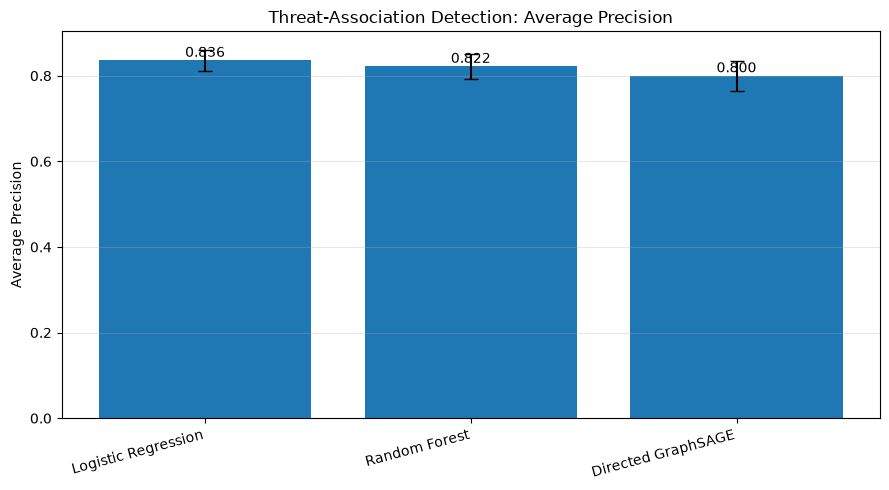

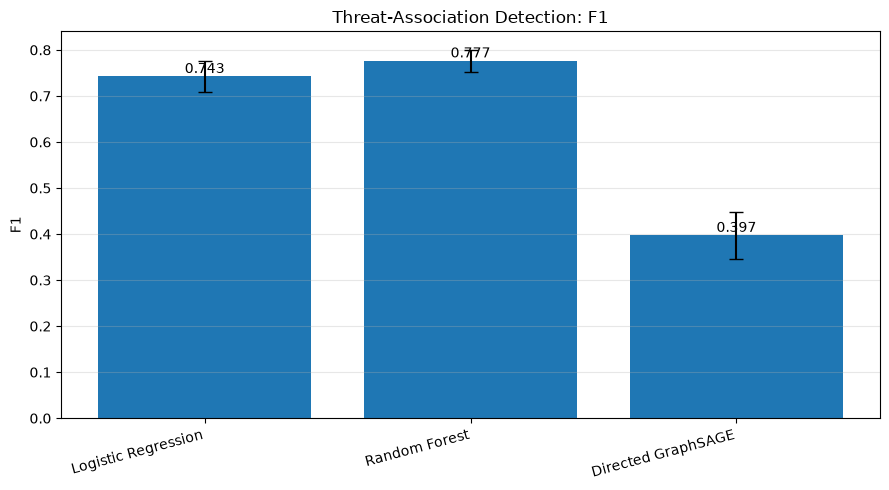

In [18]:
def plot_metric(
    metric: str,
    title: str,
    filename: str
) -> None:

    labels = (
        detection_summary_df["model"]
        .tolist()
    )
    means = detection_summary_df[
        f"{metric}_mean"
    ].to_numpy()
    errors = detection_summary_df[
        f"{metric}_std"
    ].to_numpy()

    positions = np.arange(
        len(labels)
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.bar(
        positions,
        means,
        yerr=errors,
        capsize=5
    )

    ax.set_xticks(positions)
    ax.set_xticklabels(
        labels,
        rotation=15,
        ha="right"
    )

    ax.set_ylabel(
        metric.replace(
            "_",
            " "
        ).title()
    )
    ax.set_title(title)
    ax.grid(
        axis="y",
        alpha=0.3
    )

    for position, value in zip(
        positions,
        means
    ):
        ax.text(
            position,
            value,
            f"{value:.3f}",
            ha="center",
            va="bottom"
        )

    fig.tight_layout()

    fig.savefig(
        FIGURE_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


plot_metric(
    "average_precision",
    "Threat-Association Detection: Average Precision",
    "average_precision_comparison.png"
)

plot_metric(
    "f1",
    "Threat-Association Detection: F1",
    "f1_comparison.png"
)

## 17. Representative test predictions

In [19]:
representative_condition = (
    representative_objects[
        "condition"
    ]
)

representative_graphsage = (
    representative_objects[
        "graphsage"
    ]
)

prediction_df = (
    representative_condition[
        "test_examples"
    ].copy()
)

prediction_df[
    "association_probability"
] = representative_graphsage[
    "test_probabilities"
]

representative_threshold = (
    representative_graphsage[
        "threshold"
    ]
)

prediction_df[
    "detected_association"
] = (
    prediction_df[
        "association_probability"
    ]
    >= representative_threshold
).astype(int)

prediction_df[
    "correct_detection"
] = (
    prediction_df[
        "detected_association"
    ]
    == prediction_df["label"]
)

text_lookup = dict(
    zip(
        node_df["node_index"],
        node_df["canonical_text"]
    )
)

prediction_df["source_entity"] = (
    prediction_df["source_index"]
    .map(text_lookup)
)

prediction_df["target_entity"] = (
    prediction_df["target_index"]
    .map(text_lookup)
)

prediction_df["source_entity_type"] = (
    prediction_df["source_index"]
    .map(entity_type_lookup)
)

prediction_df["target_entity_type"] = (
    prediction_df["target_index"]
    .map(entity_type_lookup)
)

display_columns = [
    "source_entity",
    "source_entity_type",
    "target_entity",
    "target_entity_type",
    "relation_type",
    "label",
    "detected_association",
    "association_probability",
    "correct_detection"
]

display(
    prediction_df[
        display_columns
    ]
    .sort_values(
        "association_probability",
        ascending=False
    )
    .head(20)
)

,source_entity,source_entity_type,target_entity,target_entity_type,relation_type,label,detected_association,association_probability,correct_detection
7,hxxp:miakhalifagame[]com,URL,c&c server,Infrastucture,related-to,1,1,1.000000,True
218,flashinstallerexe,FILEPATH,biopass rat,malware,indicates,1,1,1.000000,True
131,government,identity,taiwan,location,located-at,1,1,0.999999,True
103,test3exe,FILEPATH,biopass rat,malware,indicates,1,1,0.999999,True
226,coldriver,threat-actor,russian,location,located-at,1,1,0.999997,True
65,30ccfbf24b7c8cc15f85541d5ec18feb0e19e75e1e4d2b...,SHA2,biopass rat,malware,indicates,1,1,0.999995,True
44,anydeskmsi,tools,mimikatz,tools,drops,1,1,0.999994,True
59,apt28,threat-actor,sofacy group,threat-actor,duplicate-of,1,1,0.999994,True
199,curious gorge,threat-actor,ukraine,location,duplicate-of,1,1,0.999992,True
217,highly obfuscated powershell script,attack-pattern,mailto,malware,delivers,1,1,0.999992,True


## 18. Confusion matrix and error analysis

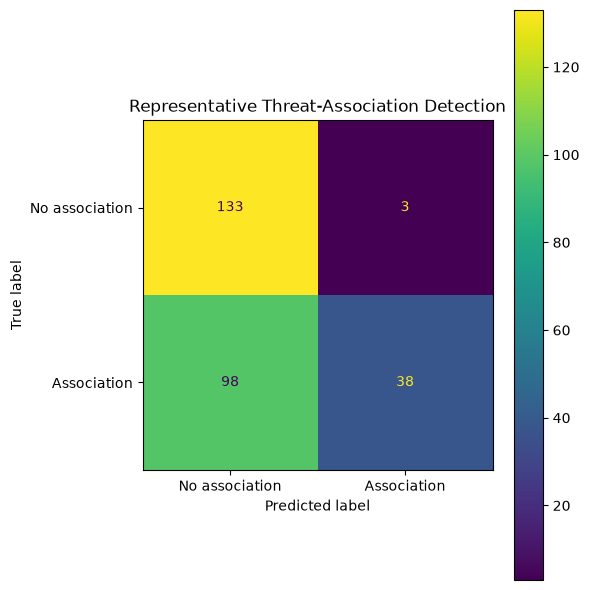

False positives: 3


,source_entity,source_entity_type,target_entity,target_entity_type,relation_type,label,detected_association,association_probability,correct_detection
74,tsar team,threat-actor,technology companies,identity,NO_EDGE,0,1,0.991433,False
243,primitive bear,threat-actor,mimikatz,tools,NO_EDGE,0,1,0.963092,False
80,nerapack,malware,winnti,threat-actor,NO_EDGE,0,1,0.808649,False


False negatives: 98


,source_entity,source_entity_type,target_entity,target_entity_type,relation_type,label,detected_association,association_probability,correct_detection
148,cve202027932,vulnerability,xnu kernel,SOFTWARE,has,1,0,2.677855e-11,False
123,“loadoerfini”,FILEPATH,code injection,attack-pattern,uses,1,0,6.029346e-11,False
216,enemybot,malware,gafgyt,malware,variant-of,1,0,7.066790e-11,False
157,european embassy,identity,moscow,location,located-at,1,0,7.218275e-11,False
251,dyreza,malware,dyre,malware,duplicate-of,1,0,7.477198e-11,False
22,deploy malicious batch scripts,attack-pattern,pdq,tools,uses,1,0,7.860526e-11,False
48,4979a10b81c41ecc0fc3a0f376ade766ce616d2301639f...,SHA2,xorist ransomware,malware,indicates,1,0,9.690638e-11,False
3,151248115146,IPV4,ladomfichisi1987@mailru,EMAIL,related-to,1,0,1.046661e-10,False
132,stolen accounts,attack-pattern,taobao,SOFTWARE,related-to,1,0,1.513028e-10,False
203,shellcode,tools,windows service,SOFTWARE,duplicate-of,1,0,1.648612e-10,False


In [20]:
matrix = confusion_matrix(
    prediction_df["label"],
    prediction_df[
        "detected_association"
    ],
    labels=[0, 1]
)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=[
        "No association",
        "Association"
    ]
).plot(
    ax=ax,
    values_format="d"
)

ax.set_title(
    "Representative Threat-Association Detection"
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR
    / "representative_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

false_positive_df = (
    prediction_df[
        (
            prediction_df["label"] == 0
        )
        & (
            prediction_df[
                "detected_association"
            ] == 1
        )
    ]
    .sort_values(
        "association_probability",
        ascending=False
    )
)

false_negative_df = (
    prediction_df[
        (
            prediction_df["label"] == 1
        )
        & (
            prediction_df[
                "detected_association"
            ] == 0
        )
    ]
    .sort_values(
        "association_probability",
        ascending=True
    )
)

print(
    "False positives:",
    len(false_positive_df)
)
display(
    false_positive_df[
        display_columns
    ].head(15)
)

print(
    "False negatives:",
    len(false_negative_df)
)
display(
    false_negative_df[
        display_columns
    ].head(15)
)

## 19. Candidate unobserved threat associations

The representative model scores plausible unobserved entity pairs.

These are **candidates for analyst review**. They are not automatically confirmed facts and should not be inserted into a production CTI graph without external validation.

In [21]:
def sample_candidate_pairs(
    sample_size: int,
    seed: int
) -> pd.DataFrame:

    rng = np.random.default_rng(seed)
    reserved = set()
    records = []

    while len(records) < sample_size:
        type_pair = (
            observed_type_pairs.iloc[
                int(
                    rng.integers(
                        0,
                        len(
                            observed_type_pairs
                        )
                    )
                )
            ]
        )

        pair = draw_valid_non_edge(
            type_pair[
                "source_type"
            ],
            type_pair[
                "target_type"
            ],
            rng,
            reserved
        )

        if pair is None:
            continue

        reserved.add(pair)

        records.append({
            "source_index": pair[0],
            "target_index": pair[1],
            "source_type": (
                entity_type_lookup[
                    pair[0]
                ]
            ),
            "target_type": (
                entity_type_lookup[
                    pair[1]
                ]
            ),
            "relation_type": (
                "UNOBSERVED_CANDIDATE"
            ),
            "label": 0
        })

    return pd.DataFrame(records)


candidate_df = sample_candidate_pairs(
    sample_size=5000,
    seed=REPRESENTATIVE_SEED
)

candidate_edge_index, _ = (
    examples_to_tensors(
        candidate_df
    )
)

representative_model = (
    representative_graphsage[
        "model_object"
    ]
)

representative_x = torch.tensor(
    representative_graphsage[
        "node_features"
    ],
    dtype=torch.float32,
    device=DEVICE
)

representative_training_edges = (
    representative_graphsage[
        "edge_index"
    ].to(DEVICE)
)

candidate_probabilities = (
    graph_edge_probabilities(
        representative_model,
        representative_x,
        representative_training_edges,
        representative_training_edges.flip(
            0
        ),
        candidate_edge_index
    )
)

candidate_df[
    "association_probability"
] = candidate_probabilities

candidate_df["source_entity"] = (
    candidate_df["source_index"]
    .map(text_lookup)
)

candidate_df["target_entity"] = (
    candidate_df["target_index"]
    .map(text_lookup)
)

top_candidates_df = (
    candidate_df
    .sort_values(
        "association_probability",
        ascending=False
    )
    .head(50)
    .reset_index(drop=True)
)

display(
    top_candidates_df[
        [
            "source_entity",
            "source_type",
            "target_entity",
            "target_type",
            "association_probability"
        ]
    ].head(20)
)

,source_entity,source_type,target_entity,target_type,association_probability
0,tropic trooper,threat-actor,command and control (c2) server,Infrastucture,0.999999
1,dragonok,threat-actor,sofacy group,threat-actor,0.999999
2,credential phishing campaigns,campaign,philippines,location,0.999999
3,unauthenticated remote code execution (rce),attack-pattern,c&c server,Infrastucture,0.999999
4,credential harvesting,attack-pattern,c2 server,Infrastucture,0.999999
5,turla,threat-actor,anydeskmsi,tools,0.999998
6,gnuboard content,SOFTWARE,trojanwin32cobeacona,malware,0.999998
7,patchwork,threat-actor,public blog or social media post to retrieve a...,Infrastucture,0.999998
8,fin7,threat-actor,scrape memory,attack-pattern,0.999997
9,biosnews[]info,DOMAIN,lockbit 20,threat-actor,0.999996


## 20. Save model, results, figures, and experiment configuration

In [22]:
baseline_seed_results_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "baseline_detection_seed_results.csv",
    index=False
)

graphsage_seed_results_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "graphsage_detection_seed_results.csv",
    index=False
)

all_results_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "all_detection_seed_results.csv",
    index=False
)

detection_summary_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "detection_summary_mean_std.csv",
    index=False
)

statistical_comparison_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "detection_statistical_comparison.csv",
    index=False
)

prediction_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "representative_detection_test_predictions.csv",
    index=False
)

false_positive_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "representative_false_positives.csv",
    index=False
)

false_negative_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "representative_false_negatives.csv",
    index=False
)

top_candidates_df.to_csv(
    DETECTION_OUTPUT_DIR
    / "top_candidate_threat_associations.csv",
    index=False
)

representative_graphsage[
    "history"
].to_csv(
    DETECTION_OUTPUT_DIR
    / "representative_training_history.csv",
    index=False
)

torch.save(
    {
        "model_type": (
            "DirectedGraphSAGELinkPredictor"
        ),
        "seed": REPRESENTATIVE_SEED,
        "state_dict": (
            representative_model.state_dict()
        ),
        "configuration": (
            GRAPHSAGE_CONFIG
        ),
        "threshold": float(
            representative_threshold
        ),
        "entity_type_categories": (
            entity_type_encoder
            .categories_[0]
            .tolist()
        )
    },
    MODEL_DIR
    / "representative_threat_association_detector.pt"
)

experiment_configuration = {
    "task": (
        "directed_binary_threat_association_detection"
    ),
    "definition": (
        "Detect whether a directed CTI association "
        "is likely to exist between two entities."
    ),
    "scope_exclusion": (
        "Not live attack, network intrusion, malware "
        "execution, or SOC incident detection."
    ),
    "evaluation_seeds": SEEDS,
    "primary_metric": (
        "average_precision"
    ),
    "threshold_selection": (
        "validation F1 only"
    ),
    "positive_edge_split": (
        "approximately 70/15/15 with rare "
        "relations retained in training"
    ),
    "negative_sampling": (
        "type-compatible unobserved directed pairs"
    ),
    "node_features": [
        "one-hot entity type",
        "log1p mention count",
        "training graph in-degree",
        "training graph out-degree"
    ],
    "leakage_control": (
        "validation and test positive edges are "
        "excluded from GraphSAGE message passing; "
        "full-graph Node2Vec embeddings are excluded"
    ),
    "graphsage_configuration": (
        GRAPHSAGE_CONFIG
    )
}

with open(
    DETECTION_OUTPUT_DIR
    / "detection_experiment_configuration.json",
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        experiment_configuration,
        file,
        indent=4
    )

print("All Notebook 9 outputs saved.")
print(
    "Output directory:",
    DETECTION_OUTPUT_DIR
)

All Notebook 9 outputs saved.
Output directory: E:\Subjects\cti-graph-project\outputs\threat_association_detection


# Final interpretation

Notebook 9 completes the two-task project:

## Classification

**Question:** What type of cybersecurity entity is this node?  
**Implemented in:** Notebooks 6 and 7.

## Detection

**Question:** Is a directed CTI association likely to exist between these two entities?  
**Implemented in:** Notebook 9.

Use the ten-seed mean ± standard deviation results rather than selecting the strongest seed.

A high-scoring unobserved pair is a candidate association for analyst review, not a confirmed cyber-threat fact. The detector does not create SOC alerts and does not detect live attacks.


**Key finding:** Unlike node classification (Notebook 7), GraphSAGE did not outperform the traditional baselines at association detection. Logistic Regression achieved significantly higher F1 and Average Precision across all 10 seeds (Wilcoxon p ≈ 0.002, GraphSAGE won 0 of 10 seeds). GraphSAGE did achieve much higher precision (0.90 vs ~0.75) but at the cost of lower recall — it is more conservative about calling an association, missing more true associations than the baselines.